## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [85]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

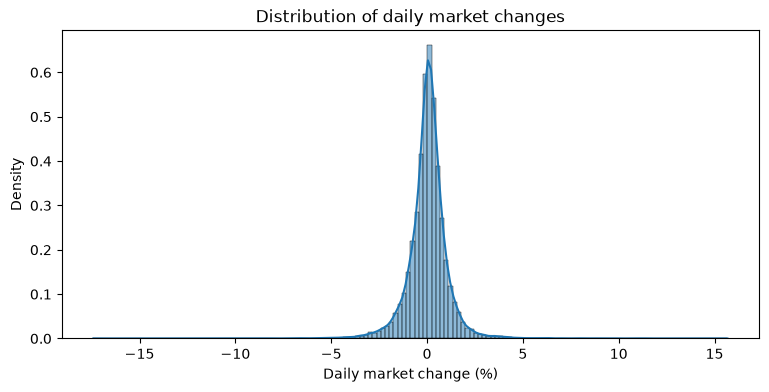

In [86]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

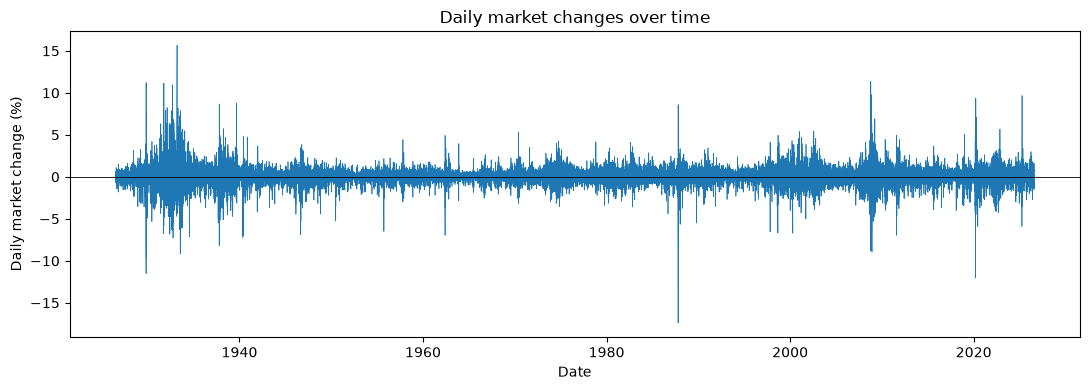

In [87]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [88]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
                                       categories=direction_categories,
                                       ordered=True)
#TODO: ADD CODE HERE

In [89]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)
#TODO: ADD CODE HERE

In [90]:
df[["direction_t", "direction_tp1"]].head()

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat


In [91]:
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins=True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


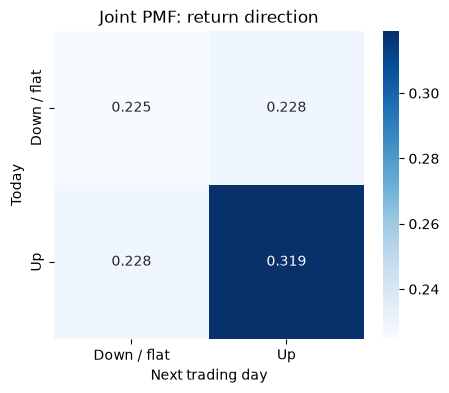

In [92]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [93]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? **It is slightly more common. The joint PMF shows that the probability of a transition to up tomorrow is 0.55, compared to a transition down of 0.45**
- Are you more likely to transition to an Up day from a Down or Up day? **It is more likely when it is an up day today.**

</div>

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [94]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=return_categories)


In [95]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [96]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['y_t'].shift(-1)

In [97]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
  - Small gain    9785
    Small loss    7452
    Near zero     3441
    Large gain    2859
    Large loss    2759
- Which are the most or least common?. **Small gain is most common, large loss is least common**
  
  </div>

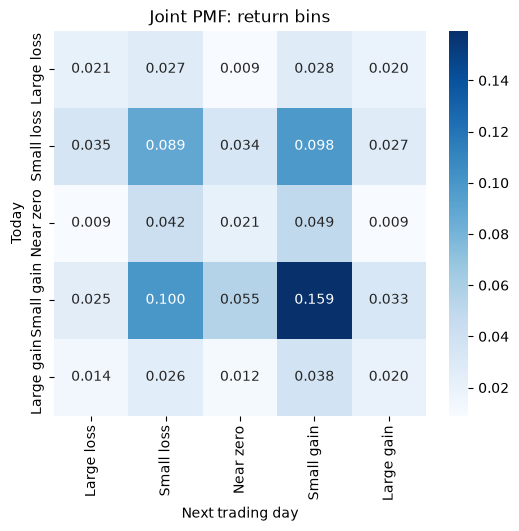

In [98]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? **The Small gain to small gain transition is most likely**

</div>

In [99]:
#conditional PMF
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


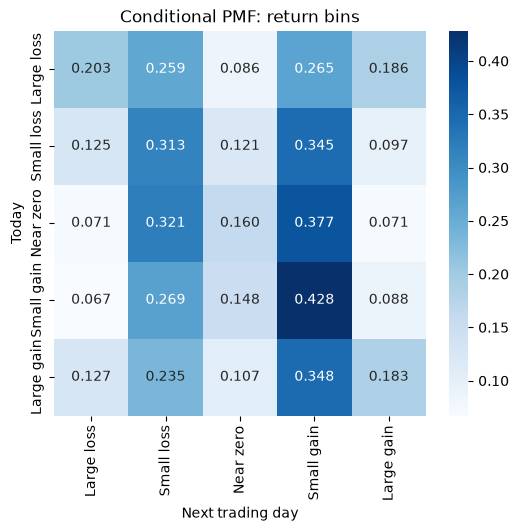

In [100]:
#conditional PMF 
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize='index'),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
    - **For all current states, the small loss and small gain transitions are the most likely.**
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
    - **The large loss row is closest to uniform, as the difference between large transitions and small transitions is smallest among all rows, though the near zero is far off from keeping it uniform. The Large gain row is next closest, and the rest are not close at all.**
- Is it relatively easy or difficult to predict the next state?
    - **It is difficult. Regardless of what today was, tomorrow's most likely states are the same, and even the most likely state with probability 0.428 is less than half.**
</div>

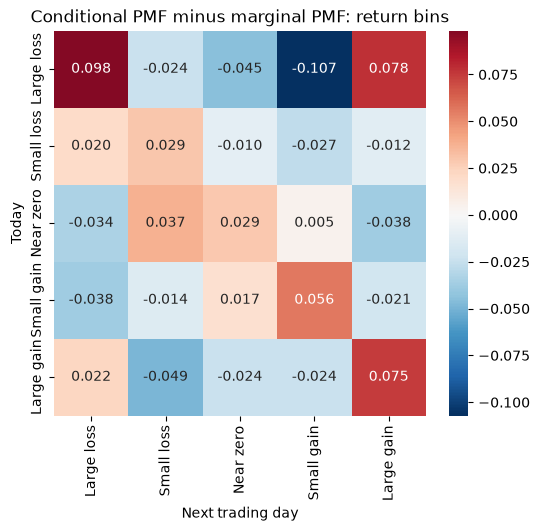

In [101]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(conditional_pmf.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF minus marginal PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
    - **LL to LL, LL to LG, LG to LG, and SG to SG are most likely. LL to SG, LG to SL, LL to NZ, SG to LL, and NZ to LG are most unlikely.**
- Does knowing today's state change the forecast for tomorrow? 
    - **It shows more about tomorrow's size of movement, not the direction. After a large move, tomorrow is likely to be large again, but it is unclear whether it goes up or down.**
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
    - **The uniform comparison assumes every state transition is equally likely, which is not true. Subtracting marginal removes the baseline frequency, and we only leave the effect of today's state.**
</div>

In [102]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')['market_return_pct_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
    - Large loss	−0.038%
        Small loss	−0.044%
        Near zero	0.015%
        Small gain	0.107%
        Large gain	0.163%
- How do the min and max values for tomorrow vary across states? 
    - **The range is largest after large moves, and narrowest after near zero days. After a large move day, both extremes get bigger.**
- Which states have the highest standard deviation for tomorrow's percent returns? 
    - **LL has the highest, and LG has the second highest.**
- Describe any patterns in the volatility you notice.
     - **It it lowest near zero and small gain and highest after large move days. Losses produce more volatility than gains in general, as LL's std of 1.72 is larger than LG's, and Small loss's std of 1.01 is larger than SG's (0.83).**
</div>


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [103]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [104]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=False)

<Axes: xlabel='y_tp1', ylabel='y_t'>

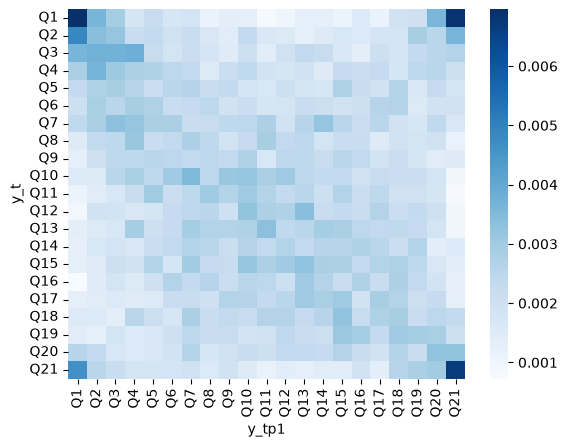

In [105]:
sns.heatmap(quantile_joint_pmf, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

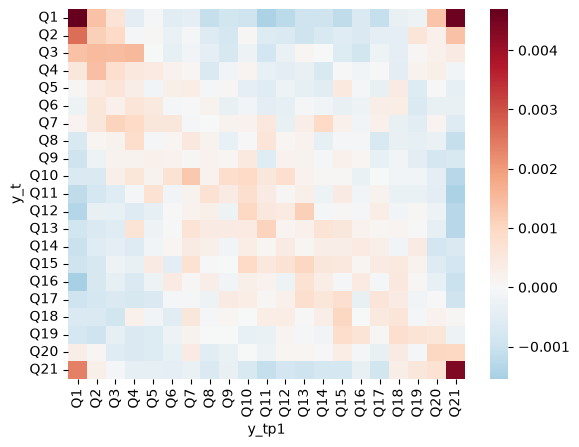

In [106]:
sns.heatmap(quantile_joint_pmf - 1/bins**2, cmap='RdBu_r', center=0)

In [107]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns? **Most of the grid is uniform, except for the four corners that stand out in dark reds. The extreme bins are the biggest losses/gains, and an extreme day is usually followed by another extreme day, while moderate days are also followed by moderate days**

</div>

<Axes: xlabel='y_tp1', ylabel='y_t'>

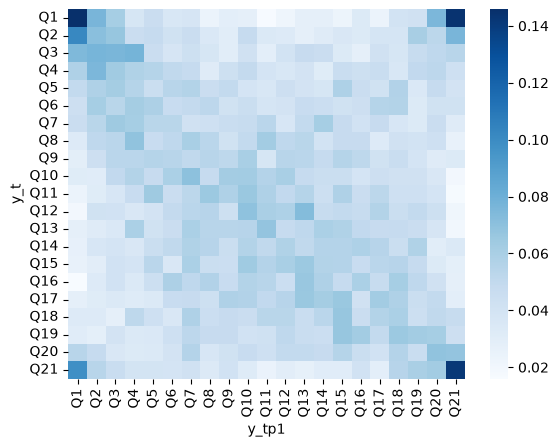

In [108]:
# compute and plot the conditional
quantile_cond_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(quantile_cond_pmf, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

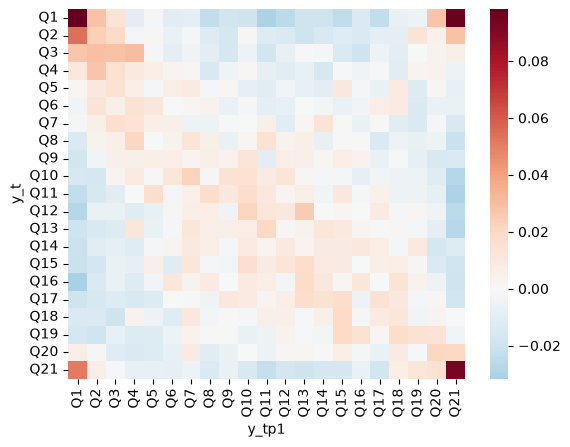

In [109]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_cond_pmf - 1/bins, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns? **It is the same pattern as the joint PMF, measured within each row. For example, after a big loss, tomorrow is more likely to be a big loss or big gain. Moderate days still follow moderate days.**

</div>

In [110]:
# compute the next day's min, mean, and max conditional on each bin
quantile_next_stats = df.groupby('y_t')['market_return_pct_tp1'].agg(['min', 'mean', 'max'])
quantile_next_stats

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


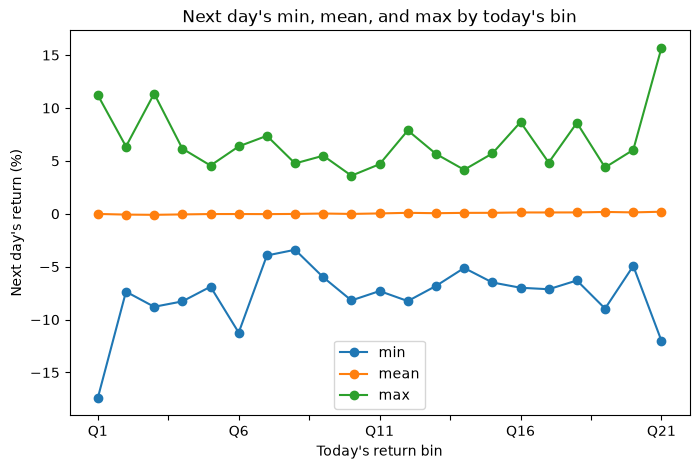

In [111]:
#plot as lines on a graph against the bins
fig, ax = plt.subplots(figsize=(8, 5))
quantile_next_stats.plot(ax=ax, marker='o')
ax.set(xlabel="Today's return bin", ylabel="Next day's return (%)",
       title="Next day's min, mean, and max by today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns? **The mean is flat around 0, while the min and max have an slight U shape, each concaving away from eachother. The min and max have dramatic falls/rises at the ends. They are much narrower in the middle bins.**

</div>

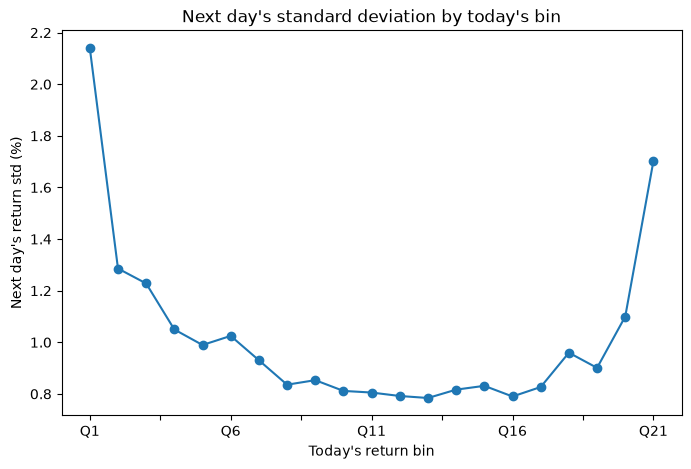

In [112]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
quantile_next_std = df.groupby('y_t')['market_return_pct_tp1'].std()

fig, ax = plt.subplots(figsize=(8, 5))
quantile_next_std.plot(ax=ax, marker='o')
ax.set(xlabel="Today's return bin", ylabel="Next day's return std (%)",
       title="Next day's standard deviation by today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns? **The std is U-shaped, lowest in the middle bins and rises sharply at both ends. Big moves are followed by more volatile days tomorrow. The curve is higher on the loss side, so large losses are followed by more volatility than large gains.**

</div>

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market? **The direction is hard to predict, but volatiility is predictable. After an extreme day, tomorrow is much more likely to be extreme, as its std is much higher. But knowing today says little about whether tomorrow will go up or down.**
</div>